# How much does retrieval matter for a small local LLM? A RAG ablation on SQuAD

**Ashhar Hussain** · ORCID [0009-0009-1568-9852](https://orcid.org/0009-0009-1568-9852)

Retrieval-augmented generation is usually evaluated end to end, which hides where answers are won or lost. This notebook separates the two stages on SQuAD v1.1 (Rajpurkar et al., 2016): the 2,067 validation paragraphs become the knowledge base, and every question has exactly one gold paragraph, so retrieval can be scored on its own before an LLM ever sees it.

**Questions**

1. How do lexical (BM25), dense (MiniLM, BGE-small), hybrid (reciprocal rank fusion) and re-ranked (cross-encoder) retrieval compare on Recall@k and MRR, and are the differences larger than resampling noise?
2. With a 0.5 B-parameter instruction model running locally on a CPU, how much answer quality comes from the retriever: closed-book vs BM25 vs the best pipeline vs the gold paragraph (an upper bound)?
3. When retrieval misses, does the model say so or make something up?
4. What does each stage cost in latency?

**Run.** Any runtime; about 25 minutes on 2 CPU cores, a few minutes on a GPU. Models and data come from the Hugging Face Hub.

In [1]:
import os, re, sys, json, time, string, random, collections, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rank-bm25", "sentence-transformers"], check=True)

import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import torch
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import logging as hub_logging
hub_logging.set_verbosity_error()
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
N_RETRIEVAL = 1000          # questions scored for retrieval
N_GEN = 400 if GPU else 150 # questions answered by the LLM in every condition
SEED = 0
rng = np.random.default_rng(SEED)
OUT = Path("outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(os.cpu_count())

path = hf_hub_download("rajpurkar/squad", "plain_text/validation-00000-of-00001.parquet", repo_type="dataset")
squad = pd.read_parquet(path)
passages = squad["context"].drop_duplicates().reset_index(drop=True)
pid = {c: i for i, c in enumerate(passages)}
squad["gold"] = squad["context"].map(pid)
print(f"{len(squad):,} questions, {len(passages):,} unique passages from {squad['title'].nunique()} articles; "
      f"median passage length {passages.str.split().str.len().median():.0f} words")

# a fixed sample of questions, spread over articles
sample = squad.sample(frac=1.0, random_state=SEED).groupby("title").head(25)  # at most 25 questions per article
sample = sample.sample(n=min(N_RETRIEVAL, len(sample)), random_state=SEED).reset_index(drop=True)
print(f"retrieval sample: {len(sample)} questions from {sample['title'].nunique()} articles")

10,570 questions, 2,067 unique passages from 48 articles; median passage length 111 words
retrieval sample: 1000 questions from 48 articles


## 1. Retrievers

* **BM25** (Okapi, k1 = 1.5, b = 0.75) on lowercased word tokens.
* **Dense**: `all-MiniLM-L6-v2` and `bge-small-en-v1.5` (with BGE's query instruction), cosine similarity over normalised embeddings. The corpus is small enough for exact search, so no approximate index is needed.
* **Hybrid**: reciprocal rank fusion of BM25 and BGE (k = 60, Cormack et al., 2009).
* **Hybrid + re-rank**: the top 20 hybrid candidates re-scored by the cross-encoder `ms-marco-MiniLM-L6-v2`.

In [2]:
tok = lambda s: re.findall(r"\w+", s.lower())
timing = {}

t0 = time.time()
bm25 = BM25Okapi([tok(p) for p in passages])
timing["BM25 index (s)"] = time.time() - t0
t0 = time.time()
bm25_scores = np.stack([bm25.get_scores(tok(q)) for q in sample.question])
timing["BM25 per query (ms)"] = 1000 * (time.time() - t0) / len(sample)


def dense_scores(model_name, q_prefix=""):
    m = SentenceTransformer(model_name, device=DEVICE)
    t0 = time.time()
    P = m.encode(passages.tolist(), batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
    t_idx = time.time() - t0
    t0 = time.time()
    Q = m.encode([q_prefix + q for q in sample.question], batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
    t_q = 1000 * (time.time() - t0) / len(sample)
    return Q @ P.T, t_idx, t_q


minilm_scores, ti, tq = dense_scores("sentence-transformers/all-MiniLM-L6-v2")
timing["MiniLM index (s)"], timing["MiniLM per query (ms)"] = ti, tq
bge_scores, ti, tq = dense_scores("BAAI/bge-small-en-v1.5", "Represent this sentence for searching relevant passages: ")
timing["BGE index (s)"], timing["BGE per query (ms)"] = ti, tq


def ranks_from_scores(S):
    return np.argsort(-S, axis=1)


def rrf(*rank_lists, k=60, depth=100):
    fused = np.zeros((rank_lists[0].shape[0], len(passages)))
    for R in rank_lists:
        for r in range(depth):
            fused[np.arange(R.shape[0]), R[:, r]] += 1.0 / (k + r + 1)
    return np.argsort(-fused, axis=1)


R = {"BM25": ranks_from_scores(bm25_scores), "MiniLM": ranks_from_scores(minilm_scores), "BGE-small": ranks_from_scores(bge_scores)}
R["Hybrid (BM25 + BGE, RRF)"] = rrf(R["BM25"], R["BGE-small"])

ce = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2", device=DEVICE)
TOPN = 20
t0 = time.time()
reranked = []
for i, q in enumerate(sample.question):
    cand = R["Hybrid (BM25 + BGE, RRF)"][i, :TOPN]
    s = ce.predict([(q, passages[c]) for c in cand], batch_size=TOPN, show_progress_bar=False)
    reranked.append(np.concatenate([cand[np.argsort(-s)], R["Hybrid (BM25 + BGE, RRF)"][i, TOPN:]]))
R["Hybrid + cross-encoder re-rank"] = np.stack(reranked)
timing["re-rank top-20 per query (ms)"] = 1000 * (time.time() - t0) / len(sample)

## 2. Retrieval quality, with uncertainty

Recall@k: share of questions whose gold paragraph is in the top k. MRR@10: mean reciprocal rank of the gold paragraph (0 if below 10). Intervals are 95% bootstrap intervals over questions; the pairwise comparison uses the paired bootstrap, since every method answers the same questions.

,R@1,R@5,R@10,R@20,MRR@10,MRR 95% CI
retriever,,,,,,
BM25,0.768,0.916,0.938,0.957,0.830,"[0.810, 0.850]"
MiniLM,0.654,0.888,0.936,0.966,0.753,"[0.730, 0.776]"
BGE-small,0.704,0.903,0.942,0.970,0.789,"[0.767, 0.810]"
"Hybrid (BM25 + BGE, RRF)",0.784,0.939,0.968,0.985,0.851,"[0.833, 0.870]"
Hybrid + cross-encoder re-rank,0.892,0.970,0.981,0.985,0.926,"[0.911, 0.939]"


,comparison,metric,difference,ci_low,ci_high,significant
0,BGE-small vs MiniLM,R@1,0.050,0.021,0.077,True
1,BGE-small vs MiniLM,R@5,0.015,-0.003,0.035,False
2,BGE-small vs BM25,R@1,-0.064,-0.097,-0.031,True
3,BGE-small vs BM25,R@5,-0.013,-0.034,0.007,False
4,"Hybrid (BM25 + BGE, RRF) vs BGE-small",R@1,0.080,0.055,0.107,True
5,"Hybrid (BM25 + BGE, RRF) vs BGE-small",R@5,0.036,0.019,0.053,True
6,Hybrid + cross-encoder re-rank vs Hybrid (BM25...,R@1,0.108,0.086,0.130,True
7,Hybrid + cross-encoder re-rank vs Hybrid (BM25...,R@5,0.031,0.018,0.044,True


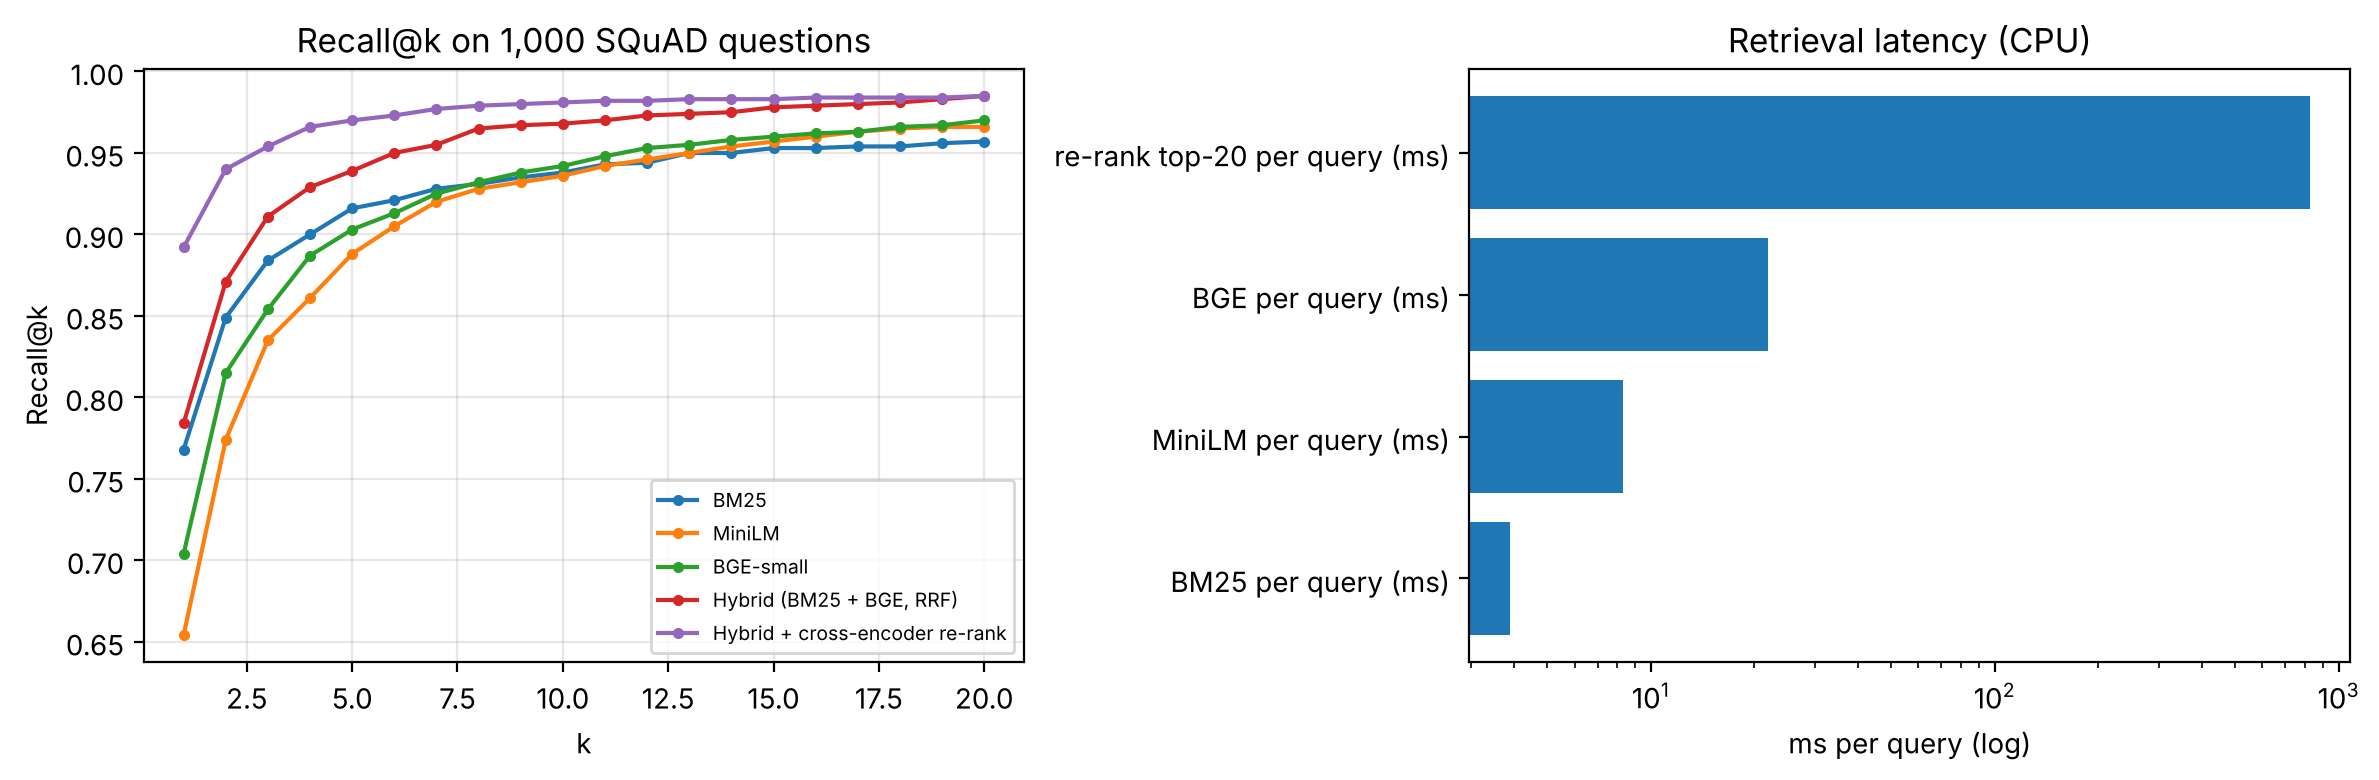

In [3]:
gold = sample.gold.values
pos = {m: np.argmax(r == gold[:, None], axis=1) for m, r in R.items()}  # 0-based rank of the gold passage
B = 2000
boot_idx = rng.integers(0, len(sample), (B, len(sample)))


def metric_table():
    rows = []
    for m, p in pos.items():
        rr = np.where(p < 10, 1.0 / (p + 1), 0.0)
        row = {"retriever": m}
        for k in (1, 5, 10, 20):
            hit = (p < k).astype(float)
            row[f"R@{k}"] = hit.mean()
        row["MRR@10"] = rr.mean()
        b = rr[boot_idx].mean(1)
        row["MRR 95% CI"] = f"[{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]"
        rows.append(row)
    return pd.DataFrame(rows).set_index("retriever")


ret = metric_table()
display(ret.round(3))


def paired(a, b, k=5):
    da, db = (pos[a] < k).astype(float), (pos[b] < k).astype(float)
    d = (da - db)[boot_idx].mean(1)
    return (da - db).mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)


comparisons = [("BGE-small", "MiniLM"), ("BGE-small", "BM25"), ("Hybrid (BM25 + BGE, RRF)", "BGE-small"),
               ("Hybrid + cross-encoder re-rank", "Hybrid (BM25 + BGE, RRF)")]
cmp_rows = []
for a, b in comparisons:
    for k in (1, 5):
        m_, lo, hi = paired(a, b, k)
        cmp_rows.append(dict(comparison=f"{a} vs {b}", metric=f"R@{k}", difference=m_, ci_low=lo, ci_high=hi, significant=not (lo <= 0 <= hi)))
cmp = pd.DataFrame(cmp_rows)
display(cmp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ks = np.arange(1, 21)
for m, p in pos.items():
    ax[0].plot(ks, [(p < k).mean() for k in ks], marker=".", label=m)
ax[0].set_xlabel("k"); ax[0].set_ylabel("Recall@k"); ax[0].set_title("Recall@k on 1,000 SQuAD questions"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
lat = pd.Series({k: v for k, v in timing.items() if "per query" in k})
ax[1].barh(lat.index, lat.values, color="#1f77b4"); ax[1].set_xscale("log"); ax[1].set_xlabel("ms per query (log)")
ax[1].set_title(f"Retrieval latency ({'GPU' if GPU else 'CPU'})")
plt.tight_layout(); fig.savefig(FIG / "retrieval.png", dpi=130); plt.show()

## 3. Does retrieval quality reach the answer?

`Qwen2.5-0.5B-Instruct`, greedy decoding, at most 24 new tokens, asked to answer with a short span or to say "unanswerable" when the context does not contain the answer. Four conditions on the same questions:

* **closed-book**: question only
* **BM25 top-3** and **best pipeline top-3** (hybrid + re-rank): three retrieved paragraphs
* **gold paragraph**: the paragraph the question was written from (upper bound for this model)

Scoring uses the official SQuAD normalisation: exact match (EM) and token F1 against all reference answers.

In [4]:
LLM = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(LLM)
dtype = torch.float16 if GPU else (torch.bfloat16 if getattr(torch.ops.mkldnn, "_is_mkldnn_bf16_supported", lambda: False)() else torch.float32)
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=dtype).to(DEVICE).eval()
SYSTEM = ("Answer the question with a short phrase copied from the context. "
          "If the context does not contain the answer, reply exactly: unanswerable.")


def prompt(q, ctx):
    if ctx is None:
        msgs = [{"role": "system", "content": "Answer the question with a short phrase."}, {"role": "user", "content": q}]
    else:
        joined = "\n\n".join(f"[{i + 1}] {c}" for i, c in enumerate(ctx))
        msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"Context:\n{joined}\n\nQuestion: {q}"}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


@torch.no_grad()
def answer(q, ctx):
    enc = tokenizer(prompt(q, ctx), return_tensors="pt").to(DEVICE)
    t0 = time.time()
    out = llm.generate(**enc, max_new_tokens=24, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    dt = time.time() - t0
    return tokenizer.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True).strip().split("\n")[0], dt, enc.input_ids.shape[1]


def norm(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())


def f1(pred, ref):
    p, r = norm(pred).split(), norm(ref).split()
    common = collections.Counter(p) & collections.Counter(r)
    same = sum(common.values())
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(r)
    return 2 * prec * rec / (prec + rec)


gen_idx = rng.choice(len(sample), N_GEN, replace=False)
best = "Hybrid + cross-encoder re-rank"
conditions = {
    "closed-book": lambda i: None,
    "BM25 top-3": lambda i: [passages[c] for c in R["BM25"][i, :3]],
    "best pipeline top-3": lambda i: [passages[c] for c in R[best][i, :3]],
    "gold paragraph": lambda i: [passages[gold[i]]],
}
# answers are appended to a JSONL file as they are produced, so an interrupted run resumes where it stopped
cache = OUT / "generations.jsonl"
done = set()
if cache.exists():
    for line in cache.read_text().splitlines():
        r_ = json.loads(line); done.add((r_["i"], r_["condition"]))
t_all = time.time()
with open(cache, "a") as fh:
    for i in gen_idx:
        q = sample.question[i]
        refs = list(sample.answers[i]["text"])
        for cname, ctx_fn in conditions.items():
            if (int(i), cname) in done:
                continue
            pred, dt, n_tok = answer(q, ctx_fn(i))
            row = dict(i=int(i), condition=cname, pred=pred, em=max(float(norm(pred) == norm(r)) for r in refs),
                       f1=max(f1(pred, r) for r in refs), abstained=norm(pred) == "unanswerable", seconds=dt, prompt_tokens=n_tok,
                       gold_in_bm25_top3=bool(pos["BM25"][i] < 3), gold_in_best_top3=bool(pos[best][i] < 3))
            fh.write(json.dumps(row) + "\n"); fh.flush()
gen = pd.DataFrame([json.loads(l) for l in cache.read_text().splitlines()])
gen = gen[gen.i.isin([int(i) for i in gen_idx])].drop_duplicates(["i", "condition"])
print(f"{len(gen):,} answers ({len(done)} loaded from a previous run), {(time.time() - t_all) / 60:.1f} min in this run")

summ = gen.groupby("condition").agg(EM=("em", "mean"), F1=("f1", "mean"), abstain=("abstained", "mean"),
                                    s_per_answer=("seconds", "mean"), prompt_tokens=("prompt_tokens", "mean")).loc[list(conditions)]
display(summ.round(3))

piv = gen.pivot(index="i", columns="condition", values="f1")
bi = rng.integers(0, len(piv), (B, len(piv)))
gen_cmp = []
for a, b in (("best pipeline top-3", "BM25 top-3"), ("BM25 top-3", "closed-book"), ("gold paragraph", "best pipeline top-3")):
    d = (piv[a] - piv[b]).values
    bd = d[bi].mean(1)
    gen_cmp.append(dict(comparison=f"{a} vs {b}", F1_difference=d.mean(), ci_low=np.percentile(bd, 2.5), ci_high=np.percentile(bd, 97.5)))
gen_cmp = pd.DataFrame(gen_cmp)
display(gen_cmp.round(4))

600 answers (0 loaded from a previous run), 6.9 min in this run


,EM,F1,abstain,s_per_answer,prompt_tokens
condition,,,,,
closed-book,0.080,0.163,0.000,0.465,33.773
BM25 top-3,0.473,0.579,0.007,0.834,571.760
best pipeline top-3,0.487,0.612,0.000,0.884,569.660
gold paragraph,0.633,0.756,0.013,0.581,222.440


,comparison,F1_difference,ci_low,ci_high
0,best pipeline top-3 vs BM25 top-3,0.0333,-0.0243,0.0894
1,BM25 top-3 vs closed-book,0.4163,0.3377,0.4953
2,gold paragraph vs best pipeline top-3,0.1443,0.0953,0.1979


## 4. When retrieval misses

,retriever,case,n,F1,abstain
0,best pipeline,gold in top-3,145,0.626,0.000
1,best pipeline,gold missed,5,0.200,0.000
2,BM25,gold in top-3,125,0.657,0.008
3,BM25,gold missed,25,0.187,0.000


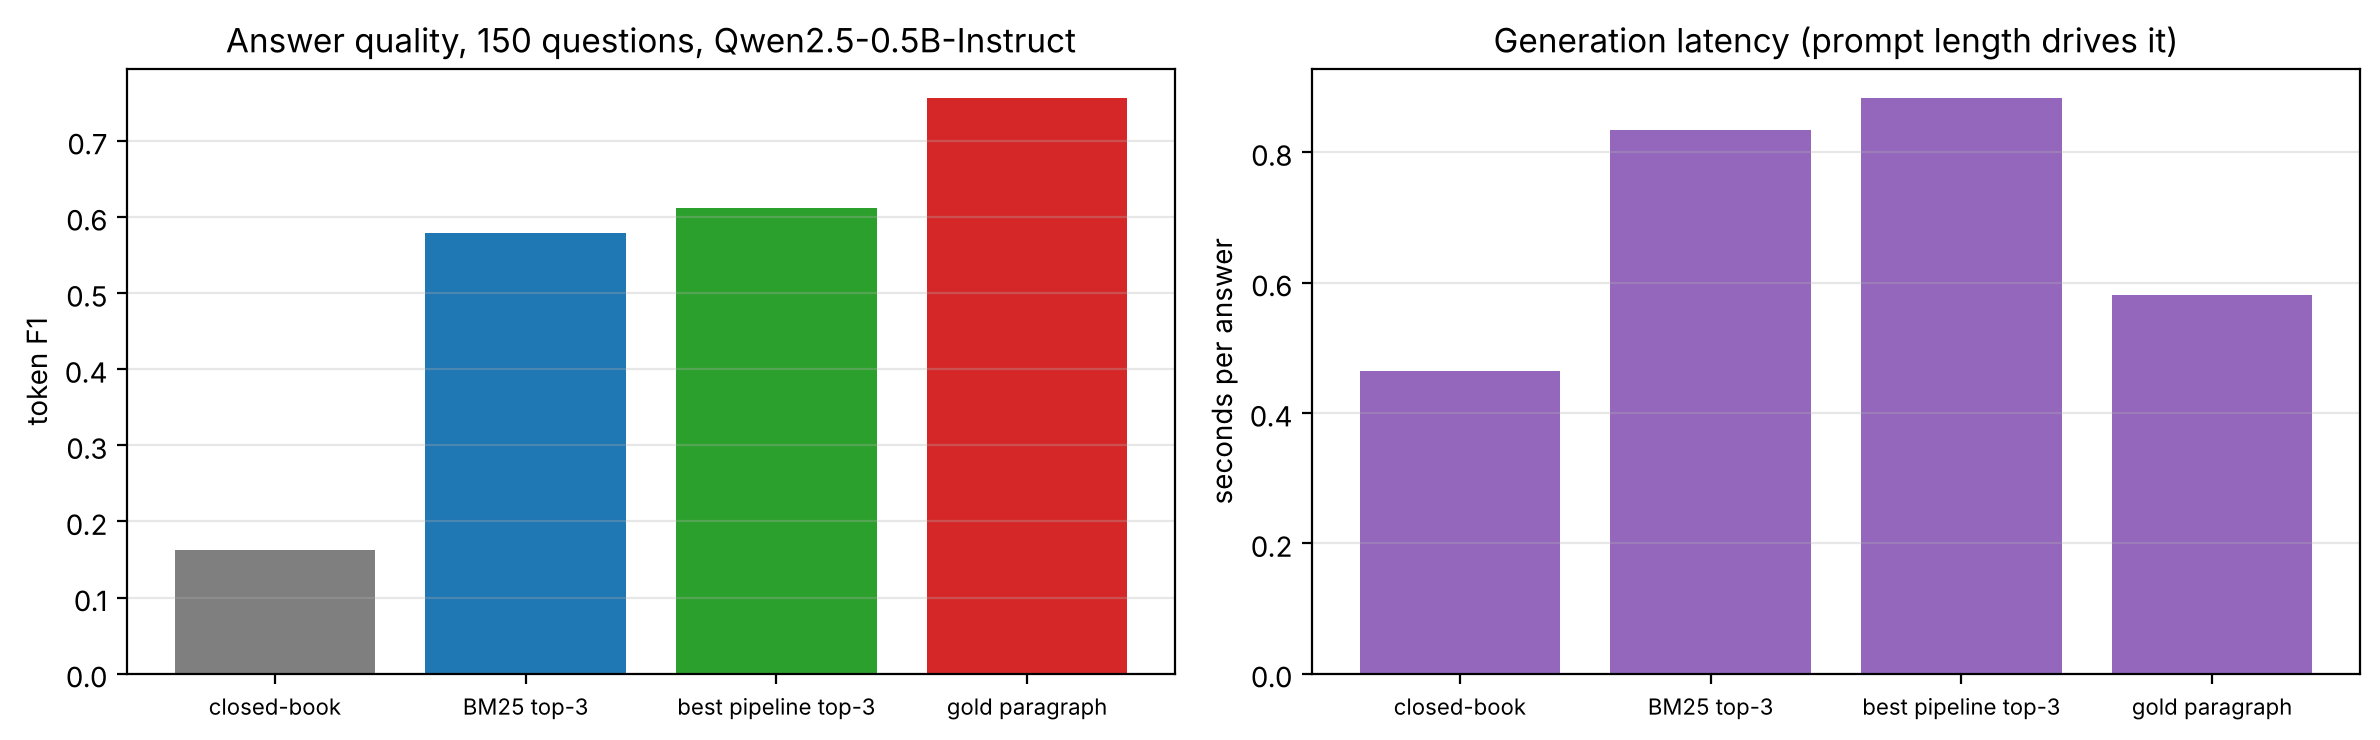

,question,pred,f1,gold_in_best_top3
2,What cancels our guilt and empowers us to resi...,Justifying grace,1.000000,True
6,What happens to waste heat in the Rankine cycle?,is removed in a condenser,0.857143,True
10,Who made up 19% of the student body in the 201...,international students,1.000000,True
14,Who did BSkyB compete with initially?,ONdigital,1.000000,True
18,Who started the IPCC Trust Fund?,The IPCC Trust Fund was established in 1989 by...,0.500000,True
22,What did Temüjin promise his followers in exch...,wealth,1.000000,True
26,What percentage of Victorians are Christian?,About 61.1% of Victorians describe themselves ...,0.222222,True
30,What Harvard Alumni was the Palestine Prime Mi...,Masaaki Shirakawa,0.000000,False


In [5]:
g = gen[gen.condition == "best pipeline top-3"]
hit, miss = g[g.gold_in_best_top3], g[~g.gold_in_best_top3]
g2 = gen[gen.condition == "BM25 top-3"]
miss_tbl = pd.DataFrame([
    dict(retriever="best pipeline", case="gold in top-3", n=len(hit), F1=hit.f1.mean(), abstain=hit.abstained.mean()),
    dict(retriever="best pipeline", case="gold missed", n=len(miss), F1=miss.f1.mean() if len(miss) else np.nan, abstain=miss.abstained.mean() if len(miss) else np.nan),
    dict(retriever="BM25", case="gold in top-3", n=int(g2.gold_in_bm25_top3.sum()), F1=g2[g2.gold_in_bm25_top3].f1.mean(), abstain=g2[g2.gold_in_bm25_top3].abstained.mean()),
    dict(retriever="BM25", case="gold missed", n=int((~g2.gold_in_bm25_top3).sum()), F1=g2[~g2.gold_in_bm25_top3].f1.mean(), abstain=g2[~g2.gold_in_bm25_top3].abstained.mean()),
])
display(miss_tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(summ.index, summ.F1, color=["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"])
ax[0].set_ylabel("token F1"); ax[0].set_title(f"Answer quality, {N_GEN} questions, {LLM.split('/')[1]}"); ax[0].tick_params(axis="x", labelsize=8)
ax[1].bar(summ.index, summ.s_per_answer, color="#9467bd"); ax[1].set_ylabel("seconds per answer"); ax[1].set_title("Generation latency (prompt length drives it)")
ax[1].tick_params(axis="x", labelsize=8)
for a in ax:
    a.grid(alpha=0.3, axis="y")
plt.tight_layout(); fig.savefig(FIG / "generation.png", dpi=130); plt.show()

examples = gen[(gen.condition == "best pipeline top-3")].merge(sample[["question"]], left_on="i", right_index=True).head(8)
display(examples[["question", "pred", "f1", "gold_in_best_top3"]])

## Findings

In [6]:
from IPython.display import Markdown
r = ret
md = "\n\n".join([
    f"**Retrieval.** On {len(sample):,} questions, Recall@1 / Recall@5 / MRR@10: " + "; ".join(
        f"{m} {r.loc[m, 'R@1']:.3f} / {r.loc[m, 'R@5']:.3f} / {r.loc[m, 'MRR@10']:.3f}" for m in r.index) + ". "
    + " ".join(f"{c.comparison} on {c.metric}: {c.difference:+.3f} [{c.ci_low:+.3f}, {c.ci_high:+.3f}]{' (significant)' if c.significant else ''}."
               for c in cmp.itertuples() if c.metric == "R@1"),
    f"**Answers.** With {LLM.split('/')[1]} on {N_GEN} questions, F1 is {summ.loc['closed-book', 'F1']:.3f} closed-book, "
    f"{summ.loc['BM25 top-3', 'F1']:.3f} with BM25, {summ.loc['best pipeline top-3', 'F1']:.3f} with the best pipeline and "
    f"{summ.loc['gold paragraph', 'F1']:.3f} with the gold paragraph. " + " ".join(
        f"{c.comparison}: {c.F1_difference:+.3f} [{c.ci_low:+.3f}, {c.ci_high:+.3f}]." for c in gen_cmp.itertuples()),
    f"**Misses.** When the best pipeline put the gold paragraph in its top 3, F1 was {hit.f1.mean():.3f}; when it missed "
    f"({len(miss)} of {len(g)} questions) F1 was {miss.f1.mean() if len(miss) else float('nan'):.3f} and the model abstained "
    f"{miss.abstained.mean() if len(miss) else float('nan'):.0%} of the time, so most misses turn into wrong answers rather than refusals.",
    f"**Latency ({'GPU' if GPU else 'CPU'}).** BM25 {timing['BM25 per query (ms)']:.1f} ms, BGE {timing['BGE per query (ms)']:.1f} ms and re-ranking "
    f"{timing['re-rank top-20 per query (ms)']:.0f} ms per query; generation {summ.loc['best pipeline top-3', 's_per_answer']:.2f} s per answer "
    f"with three paragraphs ({summ.loc['best pipeline top-3', 'prompt_tokens']:.0f} prompt tokens) against {summ.loc['closed-book', 's_per_answer']:.2f} s closed-book. "
    "Generation, not retrieval, dominates end-to-end time.",
])
(OUT / "findings.md").write_text(md)
json.dump(dict(retrieval=ret.reset_index().to_dict("records"), retrieval_comparisons=cmp.to_dict("records"),
               generation=summ.reset_index().to_dict("records"), generation_comparisons=gen_cmp.to_dict("records"),
               misses=miss_tbl.to_dict("records"), timing=timing, n_retrieval=len(sample), n_gen=N_GEN, llm=LLM),
          open(OUT / "summary.json", "w"), indent=2, default=float)
display(Markdown(md))

**Retrieval.** On 1,000 questions, Recall@1 / Recall@5 / MRR@10: BM25 0.768 / 0.916 / 0.830; MiniLM 0.654 / 0.888 / 0.753; BGE-small 0.704 / 0.903 / 0.789; Hybrid (BM25 + BGE, RRF) 0.784 / 0.939 / 0.851; Hybrid + cross-encoder re-rank 0.892 / 0.970 / 0.926. BGE-small vs MiniLM on R@1: +0.050 [+0.021, +0.077] (significant). BGE-small vs BM25 on R@1: -0.064 [-0.097, -0.031] (significant). Hybrid (BM25 + BGE, RRF) vs BGE-small on R@1: +0.080 [+0.055, +0.107] (significant). Hybrid + cross-encoder re-rank vs Hybrid (BM25 + BGE, RRF) on R@1: +0.108 [+0.086, +0.130] (significant).

**Answers.** With Qwen2.5-0.5B-Instruct on 150 questions, F1 is 0.163 closed-book, 0.579 with BM25, 0.612 with the best pipeline and 0.756 with the gold paragraph. best pipeline top-3 vs BM25 top-3: +0.033 [-0.024, +0.089]. BM25 top-3 vs closed-book: +0.416 [+0.338, +0.495]. gold paragraph vs best pipeline top-3: +0.144 [+0.095, +0.198].

**Misses.** When the best pipeline put the gold paragraph in its top 3, F1 was 0.626; when it missed (5 of 150 questions) F1 was 0.200 and the model abstained 0% of the time, so most misses turn into wrong answers rather than refusals.

**Latency (CPU).** BM25 3.9 ms, BGE 21.9 ms and re-ranking 827 ms per query; generation 0.88 s per answer with three paragraphs (570 prompt tokens) against 0.47 s closed-book. Generation, not retrieval, dominates end-to-end time.

### Limitations

* SQuAD questions were written by people looking at the paragraph, so they share many words with it; this favours BM25 compared with real user queries.
* One small model; a larger LLM would raise every generation number, but the retrieval-driven gaps are what the experiment isolates.
* Paragraphs are used as chunks; chunking strategy is not varied here.
* EM/F1 reward span overlap, not faithfulness; a judge model or human labels would be needed for that.

### References

Rajpurkar et al. (2016) *SQuAD* · Robertson & Zaragoza (2009) *The Probabilistic Relevance Framework: BM25 and Beyond* · Reimers & Gurevych (2019) *Sentence-BERT* · Xiao et al. (2023) *C-Pack: BGE embeddings* · Cormack, Clarke & Büttcher (2009) *Reciprocal Rank Fusion* · Nogueira & Cho (2019) *Passage Re-ranking with BERT* · Lewis et al. (2020) *Retrieval-Augmented Generation* · Qwen Team (2024) *Qwen2.5*